<a href="https://colab.research.google.com/github/robertbarcik/genai-in-python-tutorial/blob/main/8_tools/8_tools.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Built-in Tools: Functions OpenAI Runs For You

In the next notebook you will write functions yourself, describe them, and run them when the model asks. **Built-in tools** are that idea with one step removed: OpenAI hosts the function. You add one line to `tools=`, and the model can search the web, run Python, read your uploaded files, draw a picture, or talk to an MCP server. The "run it" step happens on their side; you just read the result.

Five tools in this notebook, each the same way: one situation, one call, one look at what came back, one price line.

## Setup

In [1]:
%pip install -q openai==3.35.1   # Colab installs here; locally, `pip install -r requirements.txt` already covers it

import os
from openai import OpenAI

# Your key, looked up in this order: Colab secret -> environment variable -> a prompt.
try:
    from google.colab import userdata
    api_key = userdata.get("OPENAI_API_KEY")
except Exception:
    api_key = os.environ.get("OPENAI_API_KEY")
if not api_key:
    from getpass import getpass
    api_key = getpass("OpenAI API key: ")

client = OpenAI(api_key=api_key)
MODEL = "gpt-5.6-luna"   # small, cheap model of the current generation (~$0.20 in / $1.20 out per 1M tokens)

# Data files: next to this notebook if you downloaded the course folder; fetched from GitHub otherwise (Colab).
import pathlib, urllib.request
RAW = "https://raw.githubusercontent.com/robertbarcik/genai-in-python-tutorial/main/8_tools/"
for name in ['company_policies.txt', 'product_catalog.txt', 'faq.txt', 'employee_data.csv']:
    if not pathlib.Path(name).exists():
        pathlib.Path(name).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(RAW + name, name)

import base64, json, time
print("Ready. Model:", MODEL)

Note: you may need to restart the kernel to use updated packages.
Ready. Model: gpt-5.6-luna


## Web search

The helpdesk bot gets asked "what is the latest Python version?". The model's knowledge stops at its training date, so on its own it would guess. With web search, it looks it up first and tells you where the answer came from.

In [2]:
response = client.responses.create(
    model=MODEL,
    tools=[{"type": "web_search"}],
    input="What is the latest stable Python release right now? One sentence, with the date.",
)

print(response.output_text)

The latest stable Python release is **Python 3.15.0**, released **October 9, 2026**. ([python.org](https://www.python.org/downloads/release/python-3150/?utm_source=openai))


### 🔍 What just happened?

The output has more than a message in it. Let's list the items, and pull out the citations the model attached to its sentence: every claim it looked up carries a URL.

In [3]:
print("Items:", [item.type for item in response.output])

message = next(item for item in response.output if item.type == "message")
for part in message.content:
    for annotation in getattr(part, "annotations", []):
        if annotation.type == "url_citation":
            print("source:", annotation.title[:60], "->", annotation.url[:80])

Items: ['reasoning', 'web_search_call', 'message']
source: Python Release Python 3.15.0 | Python.org -> https://www.python.org/downloads/release/python-3150/?utm_source=openai


A `web_search_call` item records that a search happened; the `message` carries the answer plus `url_citation` annotations. Show those links to your users. Price: about 10 USD per 1,000 searches on top of the normal tokens, so do not enable it on every request, only where fresh facts matter.

### 🎯 Mini-task

Ask something that changed this week (a sports result, a product launch) and check the citation dates.

## Code interpreter

Language models are unreliable at arithmetic and hopeless at "analyze this spreadsheet". **Code interpreter** gives the model a sandboxed Python session: it writes code, runs it, reads the result, and answers from real numbers. `container: {"type": "auto"}` tells OpenAI to start a fresh sandbox for you.

In [4]:
response = client.responses.create(
    model=MODEL,
    tools=[{"type": "code_interpreter", "container": {"type": "auto"}}],
    input="What is the compound interest on 12,500 EUR at 3.7% per year after 8 years? Use Python.",
)

print(response.output_text)

Using annual compounding:

\[
\text{Compound interest} = P\left[(1+r)^t-1\right]
\]

```python
P = 12500
r = 0.037
t = 8

interest = P * ((1 + r)**t - 1)
amount = P + interest

print(f"Interest: €{interest:,.2f}")
print(f"Final amount: €{amount:,.2f}")
```

**Compound interest: €4,216.30**  
**Final amount: €16,716.30**


### 🔍 What just happened?

The number came from Python, not from the model's intuition. The code it wrote is in the output, in a `code_interpreter_call` item, so you can audit it.

In [5]:
for item in response.output:
    if item.type == "code_interpreter_call":
        print("Code the model ran:\n" + "-" * 40)
        print(item.code)
        print("-" * 40)

Code the model ran:
----------------------------------------
P=12500
r=0.037
t=8
A=P*(1+r)**t
interest=A-P
A, interest

----------------------------------------


Now the real use: hand it a file. Upload the CSV once, pass its id to the container, and ask questions like an analyst would.

In [6]:
with open("employee_data.csv", "rb") as f:
    csv_file = client.files.create(file=f, purpose="user_data")

response = client.responses.create(
    model=MODEL,
    tools=[{"type": "code_interpreter", "container": {"type": "auto", "file_ids": [csv_file.id]}}],
    input="Analyze the employee CSV: average salary by department, and the correlation between years_experience and salary. Short answer.",
)

print(response.output_text)

- **Average salary by department:**
  - Engineering: **$110,500**
  - Finance: **$94,700**
  - Sales: **$73,800**
  - Marketing: **$71,700**
  - HR: **$66,000**

- **Correlation between years of experience and salary:** **0.948**, indicating a **very strong positive relationship**.


Price: about 0.03 USD per sandbox session (a session stays alive for a while, so several requests in a row share it), plus tokens.

### 🎯 Mini-task

Ask for a bar chart of salary by department. The image comes back as a file in the container; find its id in the output items.

## File search: RAG, hosted

In the RAG notebook you built retrieval by hand: embed, store, search, prompt. **File search** does all four for you. You upload documents into a **vector store**; OpenAI chunks and embeds them; the model searches the store when it needs to. Three company documents, three steps.

In [7]:
# 1. Upload the documents
uploaded = [client.files.create(file=open(name, "rb"), purpose="assistants")
            for name in ["company_policies.txt", "product_catalog.txt", "faq.txt"]]

# 2. Put them in a vector store and wait until they are indexed
store = client.vector_stores.create(name="TechStart knowledge base")
for f in uploaded:
    client.vector_stores.files.create(vector_store_id=store.id, file_id=f.id)

while (counts := client.vector_stores.retrieve(store.id).file_counts).completed < counts.total:
    time.sleep(1)
print(f"Indexed {counts.completed}/{counts.total} files in store {store.id}")

Indexed 3/3 files in store vs_6ad5e24d05a88191bd8f3ac956e97eed


In [8]:
# 3. Ask. The model searches the store on its own when the question needs it.
def ask_docs(question):
    response = client.responses.create(
        model=MODEL,
        tools=[{"type": "file_search", "vector_store_ids": [store.id], "max_num_results": 3}],
        include=["file_search_call.results"],          # also return the chunks that were used
        input=question,
    )
    hits = next(item for item in response.output if item.type == "file_search_call").results or []
    print(f"❓ {question}")
    print(f"   looked at: {[(h.filename, round(h.score, 2)) for h in hits]}")
    print(f"💬 {response.output_text}\n")


ask_docs("How many vacation days do employees get after 3 years?")
ask_docs("What does DataFlow Pro cost per month?")
ask_docs("What are the remote work requirements, and what equipment do remote workers get?")

❓ How many vacation days do employees get after 3 years?
   looked at: [('company_policies.txt', 0.96), ('company_policies.txt', 0.14), ('faq.txt', 0.01)]
💬 After **3 years of service**, employees receive **20 vacation days per year**. 

❓ What does DataFlow Pro cost per month?
   looked at: [('product_catalog.txt', 0.99), ('product_catalog.txt', 0.96), ('product_catalog.txt', 0.42)]
💬 DataFlow Pro has three monthly plans:

- **Starter:** $499/month
- **Professional:** $1,499/month
- **Enterprise:** $4,999/month

Larger deployments use custom pricing. 

❓ What are the remote work requirements, and what equipment do remote workers get?
   looked at: [('company_policies.txt', 0.97), ('company_policies.txt', 0.8), ('product_catalog.txt', 0.49)]
💬 TechStart employees may work remotely **up to three days per week with manager approval**. The requirements are:

- Stable internet connection—**50 Mbps recommended**
- A dedicated, distraction-free workspace
- Availability during core hours: **1

### 🔍 What just happened?

Each answer lists the file chunks it was built from and their relevance scores, exactly the "which documents were used" check from the RAG notebook, only now OpenAI did the chunking, embedding and search. The third question pulled from two files at once.

Price: storage 0.10 USD per GB per day after the first free gigabyte, plus a small fee per search call. Our three text files cost nothing to store. Delete the store when you are done with it.

In [9]:
client.vector_stores.delete(store.id)
print("deleted", store.id)

deleted vs_6ad5e24d05a88191bd8f3ac956e97eed


## Image generation as a tool

In the basic examples you called the image endpoint directly. As a *tool*, the model decides when a picture is needed and writes the prompt itself; you get the image inside the same response as the text. Handy for a chat assistant that can illustrate on request.

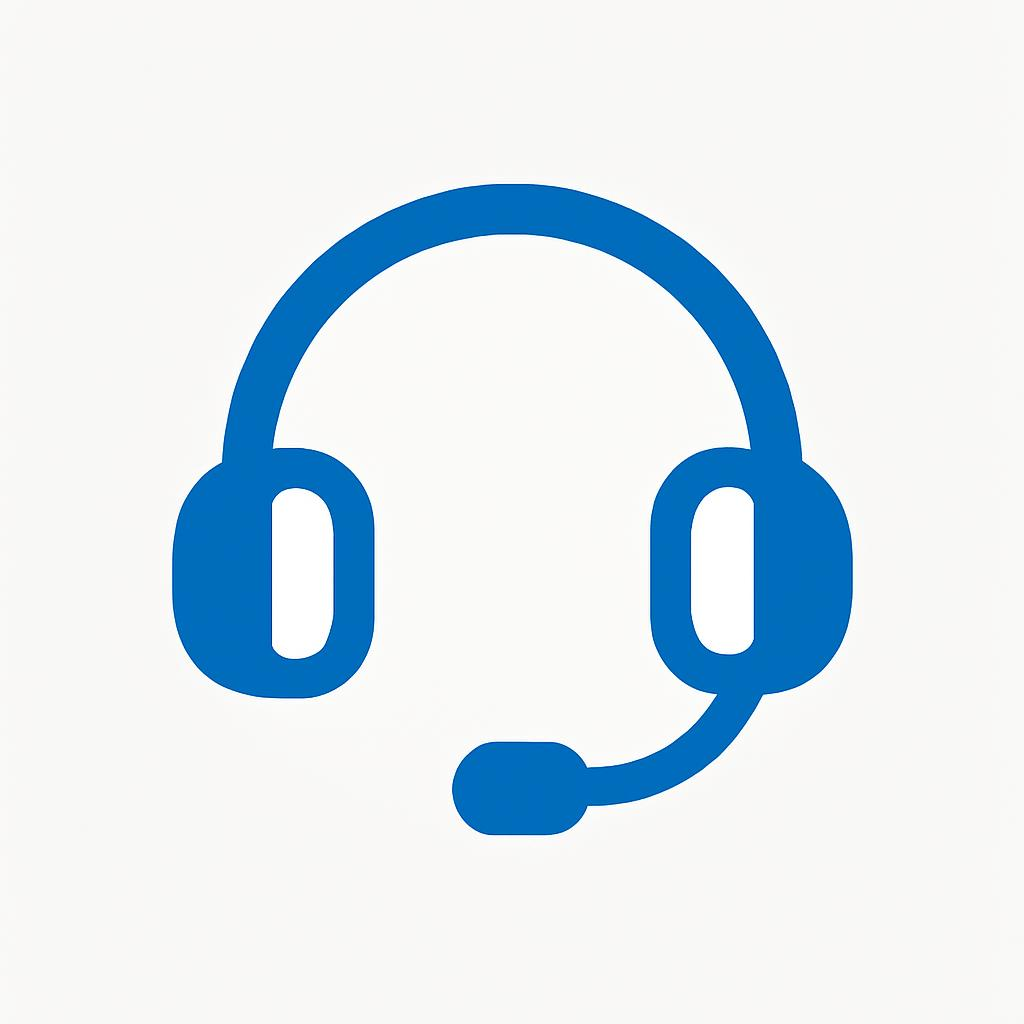

prompt the model wrote: A simple flat vector icon for a helpdesk app: a friendly blue-and-white customer support headset, symmetrical over-ear h ...



In [10]:
from IPython.display import Image, display

response = client.responses.create(
    model=MODEL,
    tools=[{"type": "image_generation", "size": "1024x1024", "quality": "low", "output_format": "jpeg"}],
    input="Make a simple flat icon for our helpdesk app: a friendly headset, blue and white. Then tell me in one line what you drew.",
)

for item in response.output:
    if item.type == "image_generation_call":
        display(Image(base64.b64decode(item.result), width=300))
        print("prompt the model wrote:", item.revised_prompt[:120], "...")
print(response.output_text)

Price: per image token, by quality and size; a low-quality 1024×1024 image is about 0.6 cents, medium about 5 cents. Keep demos on low. Docs: [developers.openai.com/api/docs/guides/tools-image-generation](https://developers.openai.com/api/docs/guides/tools-image-generation).

## Remote MCP: tools that someone else offers

With your own functions (next notebook) you write and host every one of them. **MCP (Model Context Protocol)** is the standard that lets *other* programs offer tools to your model: a server publishes a list of tools; the model discovers them and calls them; you write no glue code. Think of it as a universal adapter: any MCP server, any model.

```
your app  ──►  OpenAI  ──►  MCP server (someone else's code, e.g. GitHub docs, Stripe, your own)
              discovers the server's tools, calls them, reads the results
```

For the demo we use GitMCP, a free public server that turns any GitHub repository into searchable tools. Here it wraps OpenAI's `tiktoken` tokenizer library.

In [11]:
tiktoken_docs = {
    "type": "mcp",
    "server_label": "gitmcp",
    "server_url": "https://gitmcp.io/openai/tiktoken",
    "require_approval": "never",          # auto-approve tool calls for this demo; in production, review them
}

response = client.responses.create(
    model=MODEL,
    tools=[tiktoken_docs],
    input="Which encodings does tiktoken ship? Short list, from the repository.",
)

print(response.output_text)

`tiktoken` ships these encodings:

- `gpt2`
- `r50k_base`
- `p50k_base`
- `p50k_edit`
- `cl100k_base`
- `o200k_base`
- `o200k_harmony`

Source: [`tiktoken_ext/openai_public.py`](https://github.com/openai/tiktoken/blob/main/tiktoken_ext/openai_public.py).


### 🔍 What just happened?

The first output item is `mcp_list_tools`: the server told the model what it can do. Then come `mcp_call` items, one per tool the model decided to use. Let's print them; this is the moment you see tools you never wrote being used.

In [12]:
for item in response.output:
    if item.type == "mcp_list_tools":
        print(f"server '{item.server_label}' offers: {[t.name for t in item.tools]}")
    elif item.type == "mcp_call":
        print(f"called {item.name}({item.arguments[:60]}...)")

server 'gitmcp' offers: ['fetch_tiktoken_documentation', 'search_tiktoken_documentation', 'search_tiktoken_code', 'fetch_generic_url_content']
called fetch_tiktoken_documentation({}...)
called search_tiktoken_code({"query":"ENCODING_CONSTRUCTORS"}...)
called fetch_generic_url_content({"url":"https://raw.githubusercontent.com/openai/tiktoken/ma...)


Servers that need a login take a `headers` entry, for example `"headers": {"Authorization": "Bearer ..."}`. Price: nothing beyond the tokens. This is the bridge to agent frameworks: the next course starts by putting an MCP server behind an agent.

### 🎯 Mini-task

Point `server_url` at another public repository (`https://gitmcp.io/<owner>/<repo>`) and ask about its README.

## Combining tools

Tools stack. One request, two tools: the model searches for facts, then computes with them.

In [13]:
response = client.responses.create(
    model=MODEL,
    tools=[{"type": "web_search"}, {"type": "code_interpreter", "container": {"type": "auto"}}],
    input="Find the current populations of Slovakia and Austria, then compute the ratio Austria/Slovakia with Python. Short answer with sources.",
)

print([item.type for item in response.output])
print(response.output_text)

['reasoning', 'web_search_call', 'reasoning', 'web_search_call', 'reasoning', 'code_interpreter_call', 'message']
Using the latest official figures available:

- **Austria:** 9,217,573 (July 1, 2026) ([statistik.at](https://www.statistik.at/en/statistics/population-and-society/population/population-stock/population-at-beginning-of-year/quarter))  
- **Slovakia:** 5,403,009 (June 30, 2026) ([slovak.statistics.sk](https://slovak.statistics.sk/wps/portal/ext/products/informationmessages/inf_sprava_detail/63fa06f2-4cf5-4e9a-bc70-c26acf8cee83/%21ut/p/z0/rZBBboMwEEXP0kWWxo5tbLMMkZomaSpVUVXqTTUYmxCCIWDR5vaFA7TKoqvRLP6b9wdrnGHtYaxKCFXr4TLtH1p8vsqtStPlipD0mZHtbn98eVo_0s1bjI_W4x3WVd5EX6aJSCSVJExKxSlPRMzYjKD9YX0ose4gnFDlXYszC9xICjky1MWIixxQkjCHiCiAC1PAUhRztDpfr3qFtWl9sN8BZ20-wAkN9cxBUIcFmYF9MxmP3qKh62G8Lcg42FBP8647U4G_W_6DiGAOiHAUcTOL2ARQbiSZvAQYp4y16rdf3RXt6s27CurGLuXDD1i3Lj4%21/))  

```python
9_217_573 / 5_403_009
# 1.706007337763087
```

**Austria/Slovakia population ratio: ≈ 1.706:1**


## The rest of the toolbox

Tools you will meet in the docs but do not need on day one, one sentence each:

- **Computer use** lets the model drive a browser or desktop from screenshots: it returns clicks and keystrokes, your code executes them and sends the next screenshot. Needs a browser or VM environment and a human in the loop; see [tools-computer-use](https://developers.openai.com/api/docs/guides/tools-computer-use).
- **Shell** and **apply_patch** give the model a terminal and a way to edit files: the building blocks of coding agents.
- **Tool search** lets the model load tool definitions on demand when you have hundreds of them.
- **Async tool calling** lets the model keep talking while your slow tool is still running.

All of these are agent territory: the next course covers agents properly. Here, the point is that they are all the same shape as `{"type": "web_search"}`: one line in `tools=`.

## 🎯 Your turn

Build a "research assistant" call that uses file search over the three company documents *and* web search, and ask: "Is our remote work policy stricter than what is typical in 2026?" Check which tool the model used for which half of the answer.

Docs: [developers.openai.com/api/docs/guides/tools](https://developers.openai.com/api/docs/guides/tools).